# Hotel cancellation: project walkthrough

This notebook walks through the project with real code and real numbers:

1. **The data**: what is in it and which bookings cancel most.
2. **Finding leakage**: proving from the data that some columns contain the answer.
3. **What the split and the leaks are worth**: the same model trained four ways.
4. **Model comparison**: tuned XGBoost against Logistic Regression and Random Forest.
5. **The threshold**: choosing the cut-off by business cost, not F1.
6. **What drives predictions**: SHAP, globally and for one booking.
7. **Drift**: how the test period differs from the training period.

It reads `data/raw/hotel_bookings.csv`, the stage outputs in `artifacts/` and the production
serving bundle, so run `uv run hc-train` (or `dvc repro`) first. Nothing here writes to
`artifacts/`.

In [1]:
import os
from pathlib import Path

# Run from the project root so the configs/ and artifacts/ paths resolve.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from hotel_cancellation.components.data_ingestion import arrival_dates
from hotel_cancellation.components.data_transformation import FeatureEngineer, build_preprocessor
from hotel_cancellation.components.model_evaluation import (
    THRESHOLD_GRID,
    classification_metrics,
    expected_cost,
)
from hotel_cancellation.config.configuration import ConfigurationManager
from hotel_cancellation.monitoring.drift import build_reference_profile, detect_drift
from hotel_cancellation.pipeline.prediction_pipeline import PredictionPipeline

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CANCEL, KEEP, GREY = "#c2410c", "#0f766e", "#8a8f98"

config = ConfigurationManager()
TARGET = config.target
NUMERICAL, CATEGORICAL = config.numerical_features, config.categorical_features
COSTS = config.costs

/mnt/data/ai-engineering/Projects/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. The data

In [2]:
raw = pd.read_csv(config.get_data_ingestion_config().raw_data_path)
raw["arrival_date"] = arrival_dates(raw)
print(f"{len(raw):,} bookings, {raw.shape[1] - 1} columns")
print(f"Arrivals from {raw.arrival_date.min():%d %b %Y} to {raw.arrival_date.max():%d %b %Y}")
print(f"Cancelled: {raw[TARGET].mean():.1%}")
raw.head(3)

119,390 bookings, 32 columns
Arrivals from 01 Jul 2015 to 31 Aug 2017
Cancelled: 37.0%


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01


### Which bookings cancel?

The deposit chart shows the dataset's best-known quirk: almost every **non-refundable** booking
was cancelled. That is the opposite of what you would expect, and the model learns it.

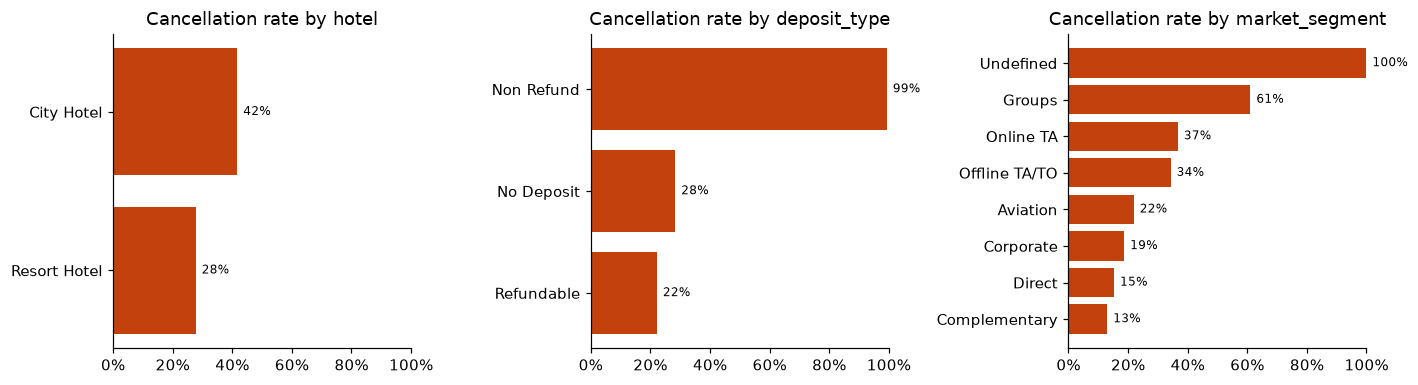

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, column in zip(axes, ["hotel", "deposit_type", "market_segment"], strict=True):
    rates = raw.groupby(column)[TARGET].mean().sort_values()
    ax.barh(rates.index, rates.values, color=CANCEL)
    ax.set_xlim(0, 1)
    ax.set_title(f"Cancellation rate by {column}")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    for y, value in enumerate(rates.values):
        ax.text(value + 0.02, y, f"{value:.0%}", va="center", fontsize=8)
plt.tight_layout()

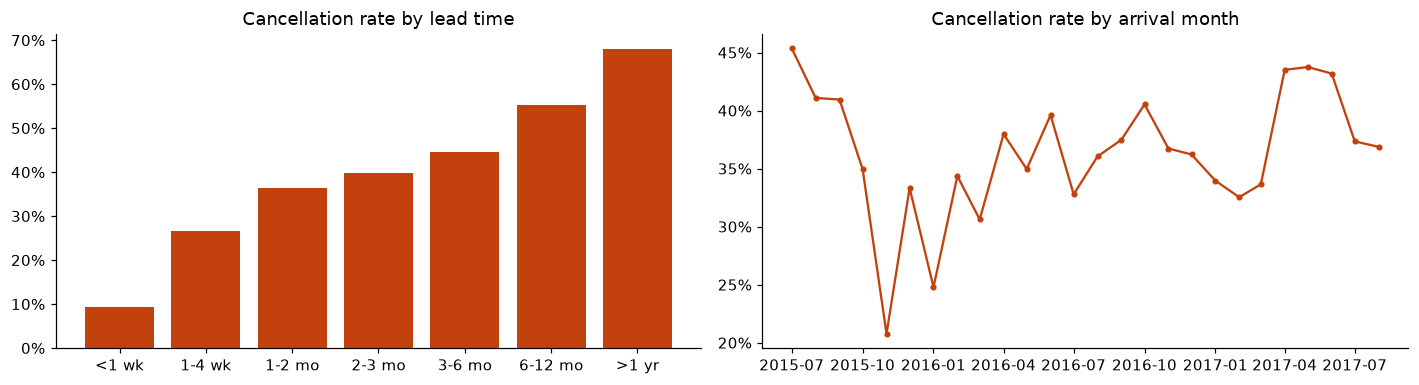

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.6))

bins = [0, 7, 30, 60, 90, 180, 365, 800]
labels = ["<1 wk", "1-4 wk", "1-2 mo", "2-3 mo", "3-6 mo", "6-12 mo", ">1 yr"]
by_lead = raw.groupby(pd.cut(raw.lead_time, bins, labels=labels, right=False), observed=True)
ax1.bar(labels, by_lead[TARGET].mean(), color=CANCEL)
ax1.set_title("Cancellation rate by lead time")
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

monthly = raw.set_index("arrival_date")[TARGET].resample("MS").mean()
ax2.plot(monthly.index, monthly.values, color=CANCEL, marker="o", markersize=3)
ax2.set_title("Cancellation rate by arrival month")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()

## 2. Finding leakage in the data

A column **leaks** when it is filled in after the outcome is known. The model then learns the
answer instead of the pattern, scores brilliantly in testing, and fails on new bookings.
Four columns obviously leak (`reservation_status`, `reservation_status_date`,
`assigned_room_type`, `booking_changes`). Two less obvious ones are tested here.

### Parking: recorded on arrival

If parking were requested at booking time, some of those guests would still cancel. Instead:

In [5]:
parking = raw.groupby(raw.required_car_parking_spaces > 0)[TARGET].agg(["mean", "size"])
parking.index = ["no parking", "parking requested"]
parking.columns = ["cancellation rate", "bookings"]
parking.style.format({"cancellation rate": "{:.2%}", "bookings": "{:,}"})

,cancellation rate,bookings
no parking,39.49%,"111,974"
parking requested,0.00%,"7,416"


Not one of the 7,416 bookings with parking cancelled. Real behaviour does not give an exact
zero. The parking space is recorded when the guest arrives, so `parking > 0` effectively means
"the guest showed up".

### Country: confirmed at check-in

Guests who never arrived are compared with guests who checked out. Cancellations and no-shows
are two different outcomes that share one thing: nobody checked in.

In [6]:
is_prt = raw.country.eq("PRT")
by_status = is_prt.groupby(raw.reservation_status).mean().rename("share from Portugal (PRT)")
by_channel = (
    raw.assign(PRT=is_prt.map({True: "PRT", False: "other"}))
    .pivot_table(index="market_segment", columns="PRT", values=TARGET, aggfunc="mean")
    .loc[["Online TA", "Offline TA/TO", "Direct", "Groups"]]
)
display(by_status.to_frame().style.format("{:.0%}"))
display(by_channel.style.format("{:.1%}").set_caption("Cancellation rate by channel and country"))

,share from Portugal (PRT)
reservation_status,
Canceled,62%
Check-Out,28%
No-Show,63%


PRT,PRT,other
market_segment,,
Online TA,45.3%,34.4%
Offline TA/TO,67.8%,1.6%
Direct,20.6%,10.8%
Groups,84.0%,7.1%


No-shows look like cancellations (≈63% PRT) and not like checked-out guests (≈28%). Within the
same channel the gap is implausible: non-Portuguese Offline TA/TO bookings almost never cancel.
This fits the country being confirmed at check-in, with PRT left as the default otherwise. So
both `country` and `required_car_parking_spaces` are listed under `leakage_columns` in
`configs/schema.yaml` and dropped at ingestion.

## 3. What the split and the leaks are worth

The same quick XGBoost model, trained four ways:

In [7]:
def quick_auc(train, test, numerical, categorical):
    pipe = Pipeline(
        [
            ("prep", build_preprocessor(numerical, categorical, min_category_frequency=50)),
            ("model", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=8, n_jobs=-1)),
        ]
    )
    pipe.fit(train.drop(columns=[TARGET]), train[TARGET])
    return roc_auc_score(test[TARGET], pipe.predict_proba(test.drop(columns=[TARGET]))[:, 1])


data = raw.drop(columns=["reservation_status", "reservation_status_date", "arrival_date"])
data["country"] = data["country"].fillna("missing")
leaky_num = NUMERICAL + ["booking_changes", "required_car_parking_spaces"]
leaky_cat = CATEGORICAL + ["assigned_room_type", "country"]

random_train, random_test = train_test_split(
    data, test_size=0.2, stratify=data[TARGET], random_state=42
)
ordered = data.loc[arrival_dates(data).sort_values(kind="stable").index]
cut = int(len(ordered) * 0.8)
time_train, time_test = ordered.iloc[:cut], ordered.iloc[cut:]

setups = {
    "Random split, leaky columns": (random_train, random_test, leaky_num, leaky_cat),
    "Random split, no leakage": (random_train, random_test, NUMERICAL, CATEGORICAL),
    "Time split, leaky columns": (time_train, time_test, leaky_num, leaky_cat),
    "Time split, no leakage (this project)": (time_train, time_test, NUMERICAL, CATEGORICAL),
}
experiment = pd.Series({name: quick_auc(*args) for name, args in setups.items()})
experiment.round(3).to_frame("test ROC-AUC")

,test ROC-AUC
"Random split, leaky columns",0.954
"Random split, no leakage",0.906
"Time split, leaky columns",0.891
"Time split, no leakage (this project)",0.827


Reading the table:

- **Rows 3 and 4** show what the check-in columns are worth on future bookings. That much of
  the old score came from columns the model cannot have when a booking is made.
- **Rows 2 and 4** show the cost of testing honestly on future bookings. A random split lets
  the model train on bookings from the same weeks it is tested on.
- **The last row** is the honest number. It is lower, and it is the one that holds up in use.

## 4. Model comparison: why (or why not) XGBoost?

All three models follow the same recipe: fit on older training rows, pick a threshold on the
newest 15% (validation), refit on all training rows, then score once on the test set. XGBoost's
hyper-parameters were also tuned with Optuna (30 trials) on the validation slice.

In [8]:
metrics = json.load(open(config.get_model_evaluation_config().metrics_path))
trainer = json.load(open(config.get_model_trainer_config().metadata_path))

rows = {"xgboost (tuned)": (trainer["validation_metrics"], metrics["candidate"])}
for name, baseline in trainer["baselines"].items():
    rows[name] = (baseline["validation_metrics"], metrics["baselines"][name])

comparison = pd.DataFrame(
    {
        name: {
            "validation ROC-AUC": val["roc_auc"],
            "test ROC-AUC": test["roc_auc"],
            "drop": val["roc_auc"] - test["roc_auc"],
            "test PR-AUC": test["pr_auc"],
            "test F1": test["f1"],
            "test cost / booking (EUR)": test["cost_per_booking"],
        }
        for name, (val, test) in rows.items()
    }
).T
comparison.round(3)

,validation ROC-AUC,test ROC-AUC,drop,test PR-AUC,test F1,test cost / booking (EUR)
xgboost (tuned),0.867,0.824,0.043,0.795,0.668,9.693
logistic_regression,0.843,0.799,0.043,0.728,0.638,10.871
random_forest,0.859,0.829,0.030,0.798,0.672,9.652


Two honest findings:

- **XGBoost does not clearly win.** On the test set, Random Forest is level with or slightly
  ahead of the tuned XGBoost, and both clearly beat Logistic Regression. The non-linear models
  are worth it. The choice between the two tree models is close.
- **Every model loses about 0.03–0.04 from validation to test.** XGBoost (tuned) and Logistic
  Regression (not tuned) drop by the same 0.043, so tuning is not the main cause. The test
  months (spring and summer) differ from the validation months (Jan–Apr 2017), and Random
  Forest copes with that slightly better (−0.030).

The project keeps XGBoost as production for now: the gap to Random Forest (0.005 ROC-AUC, under
€0.05 per booking) is small, XGBoost is faster to train and serve, and the SHAP code is built
around it. Switching models should be decided on validation results across several time
windows, not by picking the winner on the test set (that would make the test score optimistic).

## 5. The production model on the test set

In [9]:
predictor = PredictionPipeline()
test = pd.read_csv(config.get_data_ingestion_config().test_path)
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET].to_numpy()
proba = predictor.predict(X_test)["cancel_probability"].to_numpy()

print(f"Model v{predictor.version}, threshold {predictor.threshold:.3f}, {len(test):,} bookings")
pd.Series(classification_metrics(y_test, proba, predictor.threshold, COSTS)).round(3).to_frame(
    "test"
)

Model v1, threshold 0.120, 23,878 bookings


,test
roc_auc,0.824
pr_auc,0.795
brier,0.169
accuracy,0.620
precision,0.520
recall,0.936
f1,0.668
threshold,0.120
cost_per_booking,9.693
cost_saving,0.763


### Choosing the threshold by cost

F1 treats a missed cancellation and a false alarm as equally bad. A hotel does not. The costs
are set in `configs/params.yaml` (`threshold` section):

- **Missed cancellation: €100.** The room is probably left empty for a night; mean ADR is about
  €100.
- **False alarm: €20.** A retention action (reminder call, small incentive) spent on a guest who
  would have come anyway.

The threshold that minimises total cost was picked on the validation slice. Below is the same
curve on the test set:

At the chosen threshold: EUR 9.69 per booking, 76% less than flagging nothing


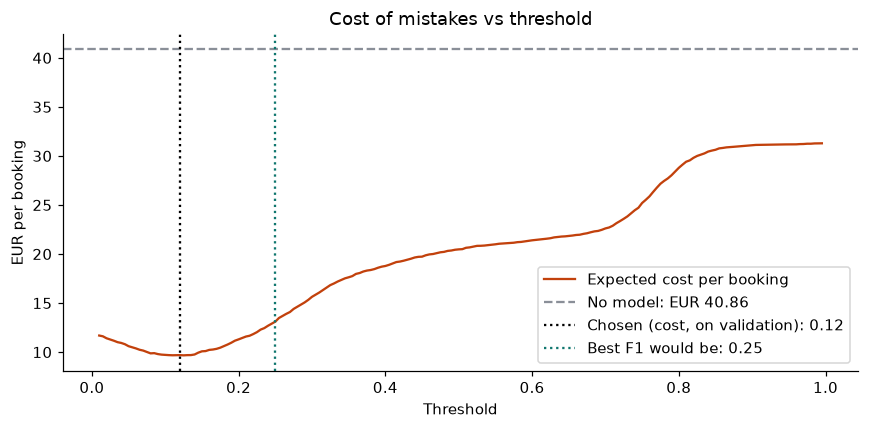

In [10]:
test_cost = [expected_cost(y_test, proba, t, COSTS) for t in THRESHOLD_GRID]
no_model = y_test.mean() * COSTS.false_negative
f1_scores = [classification_metrics(y_test, proba, t)["f1"] for t in THRESHOLD_GRID]
f1_threshold = THRESHOLD_GRID[int(np.argmax(f1_scores))]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(THRESHOLD_GRID, test_cost, color=CANCEL, label="Expected cost per booking")
ax.axhline(no_model, color=GREY, linestyle="--", label=f"No model: EUR {no_model:.2f}")
ax.axvline(
    predictor.threshold,
    color="black",
    linestyle=":",
    label=f"Chosen (cost, on validation): {predictor.threshold:.2f}",
)
ax.axvline(f1_threshold, color=KEEP, linestyle=":", label=f"Best F1 would be: {f1_threshold:.2f}")
ax.set(xlabel="Threshold", ylabel="EUR per booking", title="Cost of mistakes vs threshold")
ax.legend()
plt.tight_layout()
chosen_cost = expected_cost(y_test, proba, predictor.threshold, COSTS)
print(
    f"At the chosen threshold: EUR {chosen_cost:.2f} per booking, "
    f"{1 - chosen_cost / no_model:.0%} less than flagging nothing"
)

A missed cancellation costs five times a false alarm, so the best threshold is low: the model
flags any booking with a moderate risk. If the action were expensive (for example overbooking
a room and possibly having to relocate a guest), the false-alarm cost would rise and the
threshold would move right. That is the answer to "why not 0.5?": **the threshold encodes the
business trade-off, and changes when the costs do.**

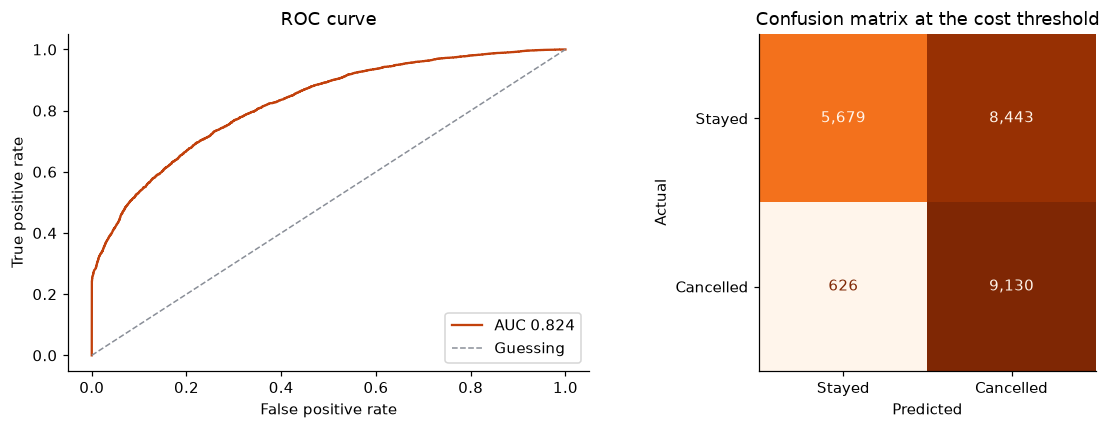

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

fpr, tpr, _ = roc_curve(y_test, proba)
axes[0].plot(fpr, tpr, color=CANCEL, label=f"AUC {roc_auc_score(y_test, proba):.3f}")
axes[0].plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="Guessing")
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(loc="lower right")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    proba >= predictor.threshold,
    display_labels=["Stayed", "Cancelled"],
    cmap="Oranges",
    colorbar=False,
    ax=axes[1],
    values_format=",",
)
axes[1].set(title="Confusion matrix at the cost threshold", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()

### Are the probabilities trustworthy?

The calibration check groups bookings by predicted probability and compares each group with
its real cancellation rate. Points on the diagonal mean "70% risk" really cancels 70% of the
time.

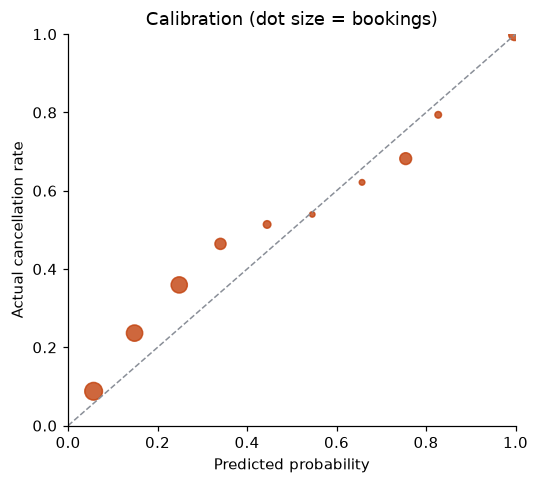

In [12]:
bands = pd.cut(proba, np.linspace(0, 1, 11), include_lowest=True)
calibration = pd.DataFrame({"predicted": proba, "actual": y_test}).groupby(bands, observed=True)
summary = calibration.mean().assign(bookings=calibration.size())

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1)
ax.scatter(summary.predicted, summary.actual, s=summary.bookings / 40, color=CANCEL, alpha=0.8)
ax.set(
    title="Calibration (dot size = bookings)",
    xlabel="Predicted probability",
    ylabel="Actual cancellation rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
plt.tight_layout()

Points above the diagonal mean bookings cancel more often than predicted on the test period.
That matches the drift in section 7: the test months (spring and summer 2017) had more
cancellations than the training period (40.9% against 36.1%). Retraining on recent months, or
adding a calibration step, would bring the points back to the line.

## 6. What drives the predictions (SHAP)

`shap.TreeExplainer` splits every prediction into one contribution per model column, in
log-odds. The prediction pipeline sums the one-hot columns back into their source feature,
so `deposit_type` appears once rather than once per deposit type. The contributions plus the
base value add up exactly to the model's output (a test checks this).

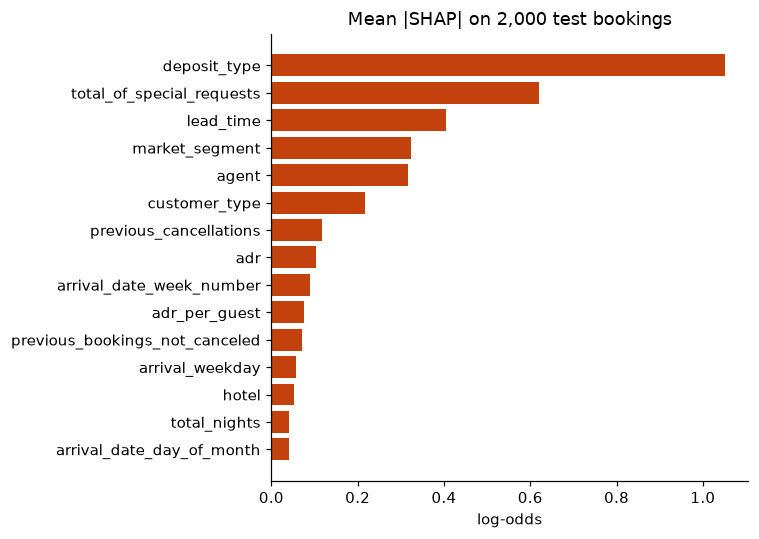

In [13]:
sample = X_test.sample(2000, random_state=0)
values = predictor.shap_values(sample)
engineered = predictor.model.named_steps["preprocessor"].named_steps["features"].transform(sample)

importance = values.abs().mean().sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance.values, color=CANCEL)
ax.set(title="Mean |SHAP| on 2,000 test bookings", xlabel="log-odds")
plt.tight_layout()

For the number features, the beeswarm also shows the *direction*. Each dot is one booking,
coloured by the feature's value. For example, red dots for `lead_time` on the right mean long
lead times push towards cancelling.

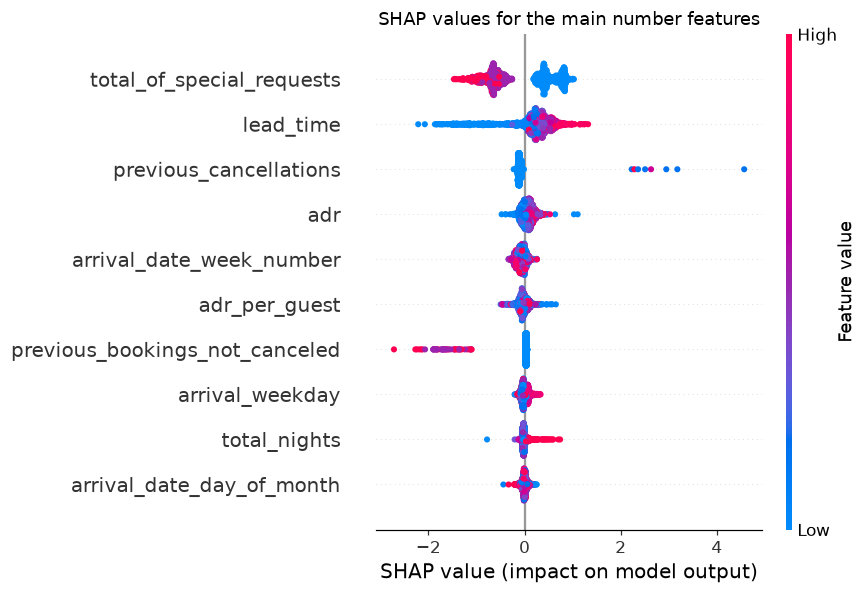

In [14]:
numeric = [c for c in importance.index[::-1] if c in NUMERICAL][:10]
shap.summary_plot(
    values[numeric].to_numpy(), engineered[numeric].astype(float), max_display=10, show=False
)
plt.title("SHAP values for the main number features")
plt.tight_layout()

### One booking, explained

In [15]:
booking = X_test.iloc[[0]]
row = predictor.shap_values(booking).iloc[0]
features = predictor.model.named_steps["preprocessor"].named_steps["features"].transform(booking)
explanation = shap.Explanation(
    values=row.to_numpy(),
    base_values=float(predictor._explainer.expected_value),
    data=features[row.index].iloc[0].to_numpy(),
    feature_names=list(row.index),
)
result = predictor.predict(booking).iloc[0]
print(
    f"Cancel probability {result.cancel_probability:.1%}: "
    f"{'flagged' if result.will_cancel else 'not flagged'} "
    f"(actual: {'cancelled' if y_test[0] else 'stayed'})"
)
shap.plots.waterfall(explanation, max_display=10, show=False)
plt.tight_layout()

Cancel probability 100.0%: flagged (actual: cancelled)


## 7. Drift between training and test

The same PSI check used by the API and the `hc-drift` command, applied to the test period.
PSI above 0.2 marks a feature as drifted. The validation stage also writes an interactive
Evidently report to `artifacts/data_validation/drift_report.html`.

In [16]:
validation = config.get_data_validation_config()
train = pd.read_csv(config.get_data_ingestion_config().train_path)
features = FeatureEngineer()
profile = build_reference_profile(
    features.transform(train), NUMERICAL, CATEGORICAL, validation.n_bins
)
report = detect_drift(
    profile,
    features.transform(test),
    validation.psi_threshold,
    validation.drift_share_threshold,
)

psi = pd.Series({name: r["psi"] for name, r in report["features"].items()}).sort_values()
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(
    psi.index,
    psi.clip(upper=1.0),
    color=[CANCEL if v > validation.psi_threshold else KEEP for v in psi],
)
ax.axvline(validation.psi_threshold, color="black", linestyle=":", label="Drift threshold")
ax.set(title="PSI by feature, train -> test (capped at 1.0)", xlabel="PSI")
ax.legend(loc="lower right")
plt.tight_layout()
print(
    f"{len(report['drifted_features'])} of {report['n_features']} features drifted; "
    f"dataset drift: {report['dataset_drift']}"
)

6 of 28 features drifted; dataset drift: False


Arrival month and week drift the most because the test period only covers April to August
2017. Price (`adr`) and lead time also shifted.

## Summary

- **Leakage found and removed.** `country` and `required_car_parking_spaces` are filled in at
  check-in. Dropping them lowers the test ROC-AUC (≈0.875 → ≈0.82), but the new number is
  the honest one.
- **The split matters most.** A random split would overstate the score by about 0.08 ROC-AUC
  (0.906 against 0.827), and the check-in columns add another 0.06 on a time split.
- **XGBoost vs baselines.** The tree models clearly beat Logistic Regression (0.82–0.83 against
  0.80). Random Forest and tuned XGBoost are within 0.005 on test. Next step: compare them with
  time-based cross-validation instead of a single validation window.
- **The threshold comes from costs** (missed cancellation €100, false alarm €20), not F1. On
  test it cuts the cost of mistakes by about three quarters compared with doing nothing.
- **Probabilities run low on the test period** because of seasonal drift. Retrain as new months
  arrive. The MLflow registry only promotes a model that beats the live one.
- **One more limitation.** The split is by *arrival* date, but predictions happen at *booking*
  time. A booking made in March for an August arrival lands in the test set by arrival, yet
  bookings made before it could arrive after the cut-off. A stricter setup splits by booking
  date (arrival minus lead time).